In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
df=pd.read_csv("forest_fire_dataset_cleaned.csv")
df = df.drop(['day', 'month', 'year'], axis=1)

In [3]:
df["Classes"] = np.where(df["Classes"].str.contains("not"),0, 1)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 241 entries, 0 to 240
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  241 non-null    int64  
 1   RH           241 non-null    int64  
 2   Ws           241 non-null    int64  
 3   Rain         241 non-null    float64
 4   FFMC         241 non-null    float64
 5   DMC          241 non-null    float64
 6   DC           241 non-null    float64
 7   ISI          241 non-null    float64
 8   BUI          241 non-null    float64
 9   FWI          241 non-null    float64
 10  Classes      241 non-null    int64  
 11  Region       241 non-null    int64  
dtypes: float64(7), int64(5)
memory usage: 22.7 KB


In [5]:
df.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0.5,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0.4,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0.0,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0.5,0,0


In [6]:
X= df.drop("FWI",axis=1)
y=df['FWI']

In [7]:
X.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
0,29,57,18,0.0,65.7,3.4,7.6,1.3,3.4,0,0
1,29,61,13,1.3,64.4,4.1,7.6,1.0,3.9,0,0
2,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0,0
3,25,89,13,2.5,28.6,1.3,6.9,0.0,1.7,0,0
4,27,77,16,0.0,64.8,3.0,14.2,1.2,3.9,0,0


In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(X,y,test_size=0.25,random_state=23)

In [9]:
X_train.shape, X_test.shape

((180, 11), (61, 11))

In [10]:
X_train.corr()

,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,Classes,Region
Temperature,1.000000,-0.655621,-0.297841,-0.320298,0.694936,0.477314,0.362681,0.607644,0.449663,0.495731,0.316780
RH,-0.655621,1.000000,0.223766,0.228508,-0.611150,-0.380028,-0.184046,-0.705364,-0.318262,-0.406602,-0.468937
Ws,-0.297841,0.223766,1.000000,0.203166,-0.135727,0.023733,0.089723,0.003336,0.055247,-0.043684,-0.212610
Rain,-0.320298,0.228508,0.203166,1.000000,-0.560721,-0.288269,-0.287600,-0.343322,-0.296135,-0.370606,-0.077746
FFMC,0.694936,-0.611150,-0.135727,-0.560721,1.000000,0.600464,0.483339,0.739310,0.582504,0.766789,0.339769
DMC,0.477314,-0.380028,0.023733,-0.288269,0.600464,1.000000,0.879161,0.656265,0.982204,0.585006,0.214469
DC,0.362681,-0.184046,0.089723,-0.287600,0.483339,0.879161,1.000000,0.459435,0.942574,0.486616,-0.056697
ISI,0.607644,-0.705364,0.003336,-0.343322,0.739310,0.656265,0.459435,1.000000,0.611890,0.739013,0.339608
BUI,0.449663,-0.318262,0.055247,-0.296135,0.582504,0.982204,0.942574,0.611890,1.000000,0.580837,0.110000
Classes,0.495731,-0.406602,-0.043684,-0.370606,0.766789,0.585006,0.486616,0.739013,0.580837,1.000000,0.251917


<Axes: >

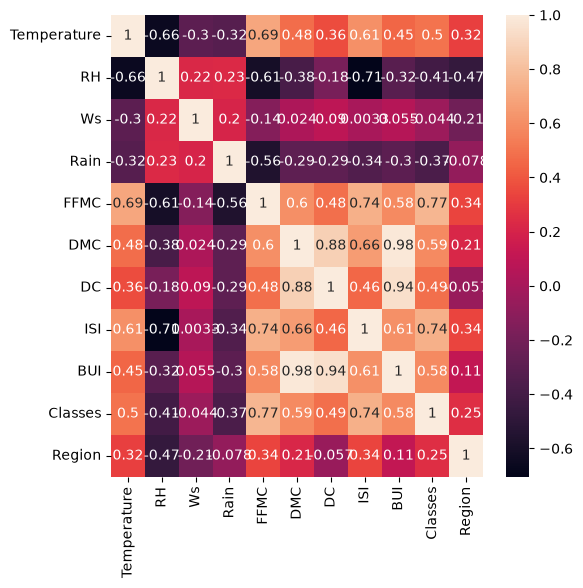

In [11]:
# Check for multi-collinearity
plt.figure(figsize=(6,6))
corr=X_train.corr()
sns.heatmap(corr,annot=True)

In [12]:
def correlation(dataset, threshold):
    col_corr = set()
    corr_matrix = dataset.corr()
    for i in range(len(corr_matrix.columns)):
        for j in range(i):
            if abs(corr_matrix.iloc[i, j]) > threshold: 
                colname = corr_matrix.columns[i]
                col_corr.add(colname)
    return col_corr

In [13]:
corr_features=correlation(X_train,0.85)
print(corr_features)

{'DC', 'BUI'}


In [14]:
X_train.drop(corr_features,axis=1,inplace=True)
X_test.drop(corr_features,axis=1,inplace=True)
X_train.head()

,Temperature,RH,Ws,Rain,FFMC,DMC,ISI,Classes,Region
38,32,68,14,1.4,66.6,7.7,1.1,0,0
86,31,78,18,0.0,85.8,45.6,4.7,1,0
120,26,80,16,1.8,47.4,2.9,0.3,0,0
52,27,66,22,0.4,68.2,10.5,1.8,0,0
30,29,68,19,1.0,59.9,2.5,1.1,0,0


In [25]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Text(0.5, 1.0, 'X_train After Scaling')

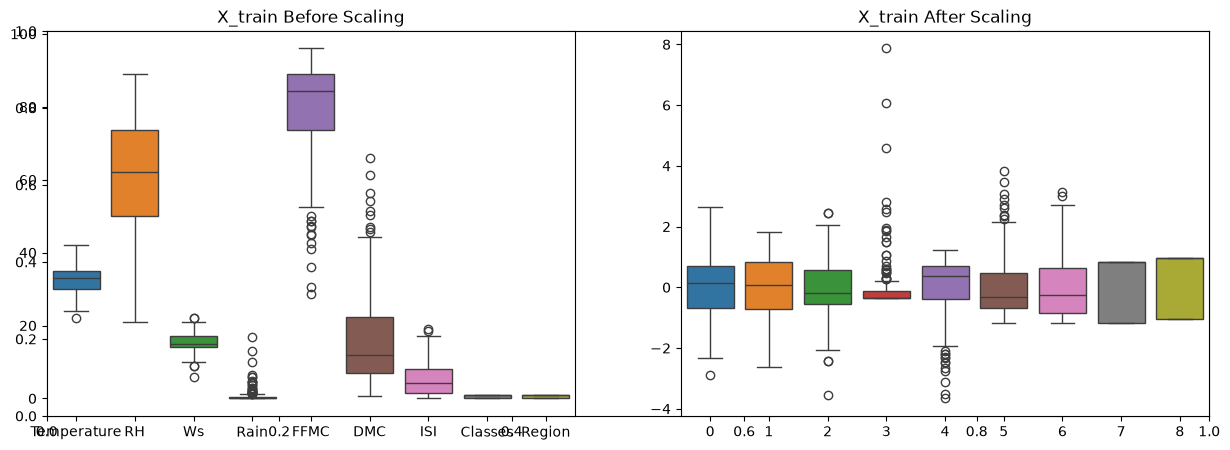

In [26]:
# comparing two plots

plt.subplots(figsize=(15,5))
plt.subplot(1,2,1)
sns.boxplot(data= X_train)
plt.title('X_train Before Scaling')
plt.subplot(1, 2, 2)
sns.boxplot(data=X_train_scaled)
plt.title('X_train After Scaling')

Mean absolute error = 0.7314729931466911
R2 score = 0.9687932102883755


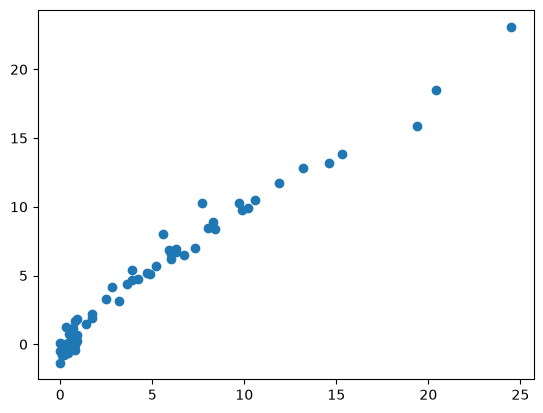

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

lin_reg=LinearRegression()
lin_reg.fit(X_train_scaled,y_train)
y_pred = lin_reg.predict(X_test_scaled)

mae =mean_absolute_error(y_test,y_pred)
score= r2_score(y_test,y_pred)

print(f"Mean absolute error = {mae}")
print(f"R2 score = {score}")
plt.scatter(y_test,y_pred)

Mean absolute error = 0.7520409164596307
R2 score = 0.9674176727168661


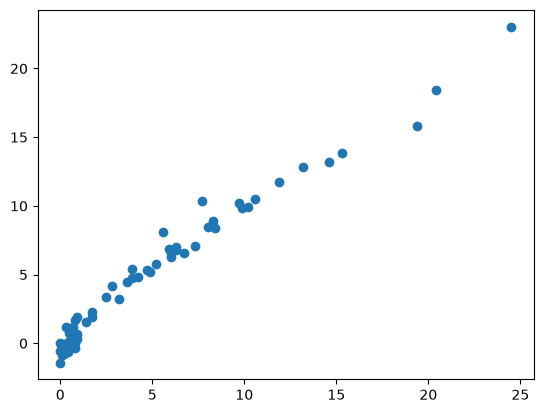

In [18]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

ridge=Ridge()
ridge.fit(X_train_scaled,y_train)
y_pred = ridge.predict(X_test_scaled)

mae =mean_absolute_error(y_test,y_pred)
score= r2_score(y_test,y_pred)

print(f"Mean absolute error = {mae}")
print(f"R2 score = {score}")
plt.scatter(y_test,y_pred)

Mean absolute error = 1.0741359304720568
R2 score = 0.9350943842815869


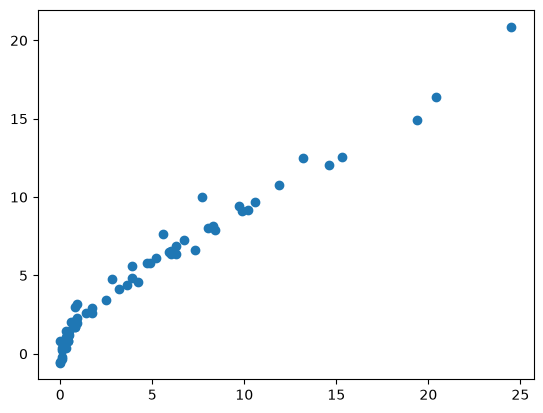

In [19]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

lasso=Lasso()
lasso.fit(X_train_scaled,y_train)
y_pred = lasso.predict(X_test_scaled)

mae =mean_absolute_error(y_test,y_pred)
score= r2_score(y_test,y_pred)

print(f"Mean absolute error = {mae}")
print(f"R2 score = {score}")
plt.scatter(y_test,y_pred)

Mean absolute error = 1.726170479592355
R2 score = 0.8435725932138929


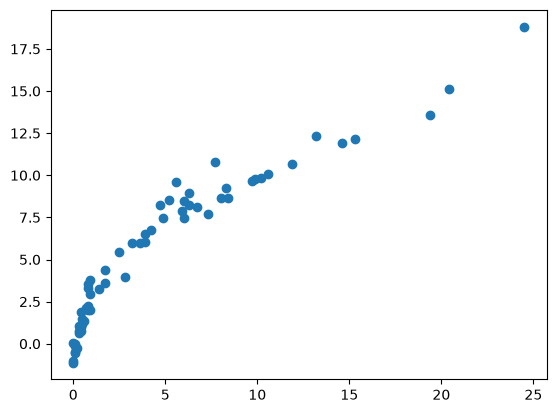

In [20]:
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

El_net=ElasticNet()
El_net.fit(X_train_scaled,y_train)
y_pred = El_net.predict(X_test_scaled)

mae =mean_absolute_error(y_test,y_pred)
score= r2_score(y_test,y_pred)

print(f"Mean absolute error = {mae}")
print(f"R2 score = {score}")
plt.scatter(y_test,y_pred)

In [21]:
from sklearn.linear_model import LassoCV
Lassocv = LassoCV(cv = 5)
Lassocv.fit(X_train,y_train)
print(Lassocv.alpha_)
print(Lassocv.alphas_)
print(len(Lassocv.alphas_))
Lassocv.predict(X_train_scaled)

0.08911502222222223
[89.11502222 83.10896798 77.5077017  72.28394201 67.41224625 62.86888647
 58.63173394 54.6801513  50.99489211 47.55800706 44.35275655 41.36352921
 38.57576578 35.97588827 33.55123381 31.28999294 29.18115214 27.21444015
 25.38027797 23.66973218 22.07447145 20.58672596 19.19924953 17.90528437
 16.69852813 15.57310322 14.52352818 13.54469099 12.63182415 11.78048148
 10.98651646 10.24606202  9.55551173  8.91150222  8.3108968   7.75077017
  7.2283942   6.74122462  6.28688865  5.86317339  5.46801513  5.09948921
  4.75580071  4.43527566  4.13635292  3.85757658  3.59758883  3.35512338
  3.12899929  2.91811521  2.72144402  2.5380278   2.36697322  2.20744715
  2.0586726   1.91992495  1.79052844  1.66985281  1.55731032  1.45235282
  1.3544691   1.26318242  1.17804815  1.09865165  1.0246062   0.95555117
  0.89115022  0.83108968  0.77507702  0.72283942  0.67412246  0.62868886
  0.58631734  0.54680151  0.50994892  0.47558007  0.44352757  0.41363529
  0.38575766  0.35975888  0.335

c:\Users\MAHAK SINGH\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LassoCV was fitted with feature names
  warnings.warn(


array([-2.93761364e-01,  1.44792380e+00, -5.42518720e-01, -3.46327962e-02,
       -3.83219908e-01, -1.08447482e+00,  1.23932433e+00, -2.59992352e-01,
        8.31715686e-01,  1.33814085e-03,  8.95222238e-01,  8.13095524e-01,
       -5.01197789e-01,  2.02088007e-01,  1.76898992e-02,  3.83384346e-02,
        3.97249518e+00,  5.29816931e-01,  2.86556227e+00, -3.17707388e-01,
       -9.83712817e-01,  2.23802373e+00,  1.18376580e+00, -9.81428470e-01,
        1.48406851e+00,  2.19219847e+00,  1.58218193e+00,  9.34795345e-01,
       -6.08546904e-01, -5.27858627e-01, -1.47054354e+00,  3.06594162e+00,
        2.20864729e+00, -3.38781471e-01,  2.43528937e-01, -4.13523302e-01,
        1.06688427e+00, -2.79625877e-01,  2.45294399e+00,  1.39587015e+00,
        2.43575522e+00,  1.05579490e+00, -2.16571293e-01, -6.79512234e-01,
       -1.67115857e-01,  3.91678872e-01, -6.58362138e-01,  3.64702000e+00,
       -1.00563914e+00,  4.51408356e-01, -6.45712739e-02,  1.13336765e+00,
        6.18075390e-01, -

In [22]:
from sklearn.linear_model import ElasticNetCV
elasticcv=ElasticNetCV(cv=5)
elasticcv.fit(X_train_scaled,y_train)

,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"l1_ratio l1_ratio: float or list of float, default=0.5Float between 0 and 1 passed to ElasticNet (scaling betweenl1 and l2 penalties). For ``l1_ratio = 0``the penalty is an L2 penalty. For ``l1_ratio = 1`` it is an L1 penalty.For ``0 < l1_ratio < 1``, the penalty is a combination of L1 and L2This parameter can be a list, in which case the differentvalues are tested by cross-validation and the one giving the bestprediction score is used. Note that a good choice of list ofvalues for l1_ratio is often to put more values close to 1(i.e. Lasso) and less close to 0 (i.e. Ridge), as in ``[.1, .5, .7,.9, .95, .99, 1]``.",0.5
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path, used for each l1_ratio.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",100
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as argument.",'auto'
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"verbose verbose: bool or int, default=0Amount of verbosity.",0
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [23]:
from sklearn.linear_model import LassoCV
Lassocv = LassoCV(cv = 5)
Lassocv.fit(X_train,y_train)

,"cv cv: int, cross-validation generator or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- int, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For int/None inputs, :class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"eps eps: float, default=1e-3Length of the path. ``eps=1e-3`` means that``alpha_min / alpha_max = 1e-3``.",0.001
,"alphas alphas: array-like or int, default=100Values of alphas to test along the regularization path.If int, `alphas` values are generated automatically.If array-like, list of alpha values to use... versionchanged:: 1.7 `alphas` accepts an integer value which removes the need to pass `n_alphas`.",100
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: 'auto', bool or array-like of shape (n_features, n_features), default='auto'Whether to use a precomputed Gram matrix to speed upcalculations. If set to ``'auto'`` let us decide. The Grammatrix can also be passed as an argument.",'auto'
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``.",0.0001
,"copy_X copy_X: bool, default=TrueIf ``True``, `X` will be copied; otherwise, it may be overwritten.",True
,"verbose verbose: bool or int, default=FalseAmount of verbosity.",False
,"n_jobs n_jobs: int, default=NoneNumber of CPUs to use during the cross validation.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"positive positive: bool, default=FalseIf positive, restrict regression coefficients to be positive.",False


In [24]:
from sklearn.linear_model import RidgeCV
ridgecv=RidgeCV(cv=5)
ridgecv.fit(X_train_scaled,y_train)

,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the efficient Leave-One-Out cross-validation- integer, to specify the number of folds,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used, else,:class:`~sklearn.model_selection.KFold` is used.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.",5
,"alphas alphas: array-like of shape (n_alphas,), default=(0.1, 1.0, 10.0)Array of alpha values to try.Regularization strength; must be a positive float. Regularizationimproves the conditioning of the problem and reduces the variance ofthe estimates. Larger values specify stronger regularization.Alpha corresponds to ``1 / (2C)`` in other linear models such as:class:`~sklearn.linear_model.LogisticRegression` or:class:`~sklearn.svm.LinearSVC`.If using Leave-One-Out cross-validation, alphas must be strictly positive.For an example on how regularization strength affects the model coefficients,see :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`.","(0.1, ...)"
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto false, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"scoring scoring: str, callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: negative :ref:`mean squared error <mean_squared_error>` if cv is None (i.e. when using leave-one-out cross-validation), or :ref:`coefficient of determination <r2_score>` (:math:`R^2`) otherwise.",None
,"gcv_mode gcv_mode: {'auto', 'svd', 'eigen'}, default='auto'Flag indicating which strategy to use when performingLeave-One-Out Cross-Validation. Options are:: 'auto' : same as 'eigen' 'svd' : use singular value decomposition of X when X is dense, fallback to 'eigen' when X is sparse 'eigen' : use eigendecomposition of X X' when n_samples <= n_features or X' X when n_features < n_samplesThe 'auto' mode is the default and is intended to pick the cheaperoption depending on the shape and sparsity of the training data.",None
,"store_cv_results store_cv_results: bool, default=FalseFlag indicating if the cross-validation values corresponding toeach alpha should be stored in the ``cv_results_`` attribute (seebelow). This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionchanged:: 1.5 Parameter name changed from `store_cv_values` to `store_cv_results`.",False
,"alpha_per_target alpha_per_target: bool, default=FalseFlag indicating whether to optimize the alpha value (picked from the`alphas` parameter list) for each target separately (for multi-outputsettings: multiple prediction targets). When set to `True`, afterfitting, the `alpha_` attribute will contain a value for each target.When set to `False`, a single alpha is used for all targets.This flag is only compatible with ``cv=None`` (i.e. usingLeave-One-Out Cross-Validation)... versionadded:: 0.24",False
Name,Type,Value
"alpha_ alpha_: float or ndarray of shape (n_targets,)Estimated regularization parameter, or, if ``alpha_per_target=True``,the estimated regularization parameter for each target.",float64,1
"best_score_ best_score_: float or ndarray of shape (n_targets,)Score of base estimator with best alpha, or, if``alpha_per_target=True``, a score for each target... versionadded:: 0.23",float64,0.9637
"coef_ coef_: ndarray of shape (n_features) or (n_targets, n_features)Weight vector(s).","ndarray[float64](9,)","[-0.09,-0.33,-0.01,..., 4.73, 0.58,-0.47]"
